# Предобработка данных и регрессия на датасете «House Prices»

**Дисциплина:** Машинное обучение и ИИ
**Модуль 2:** Предобработка данных и базовые алгоритмы регрессии/классификации
**Датасет:** House Prices – Advanced Regression Techniques

**Выполнил:** Девяткова Анастасия Александровна
**Группа:** АСОиУб-23-2
**Преподаватель:** Спирин Игорь Сергеевич

**Ссылка на репозиторий:** `https://github.com/Devjatkova/ml-course-devyatkova`
**Путь к модулю:** `module-2-house-prices/notebook.ipynb`

**Дата сдачи:** 2026-11-03

## Введение

**Задача:** Регрессия — предсказать цену продажи дома (`SalePrice`). Это непрерывная величина в долларах США. В отличие от классификации, где мы предсказываем класс (например, "выживет"/"не выживет"), здесь мы предсказываем число.

**ML-проект для регрессии** — это полный цикл работ: загрузка и разведка данных (EDA), обработка пропусков и выбросов, создание новых признаков (Feature Engineering), обучение и сравнение нескольких моделей, оценка их качества и, наконец, интерпретация результатов и создание функции для предсказания цены нового дома.

**Почему это регрессия, а не классификация?** Целевая переменная `SalePrice` является непрерывной. Мы предсказываем конкретную сумму в долларах, а не дискретный класс. Метрики качества также отличаются: в регрессии мы измеряем ошибку в долларах (RMSE, MAE), а не точность попадания в класс (Accuracy).

**Какая метрика важнее?** Для этой задачи **RMSE (Root Mean Squared Error)** является наиболее важной метрикой. RMSE сильно штрафует модель за большие ошибки (т.к. ошибка возводится в квадрат). При предсказании цены дома ошибка в $10,000 гораздо серьёзнее, чем ошибка в $1,000, и RMSE это отражает. R² показывает, какую долю дисперсии целевой переменной объяснила модель, что также очень информативно.

**Цель работы:**
1.  Провести полный разведочный анализ данных (EDA) для датасета House Prices.
2.  Обучить и сравнить 4+ модели регрессии, достигнув R² ≥ 0.90 на тестовой выборке.
3.  Реализовать функцию предсказания цены нового дома на основе обученной модели.

## Теоретическая часть

**Регрессия** — это тип задачи машинного обучения, в которой модель учится предсказывать непрерывное числовое значение на основе входных признаков. В отличие от классификации, где ответом является метка класса из фиксированного набора (например, "спам"/"не спам"), регрессия предсказывает число, которое может быть любым в заданном диапазоне. Примеры: предсказание температуры, стоимости акций или цены дома.

**Пропуски (NaN)** — это отсутствующие значения в данных. Они могут возникать по разным причинам:
1.  **MCAR (Missing Completely at Random):** Пропуск не зависит ни от каких данных. Например, датчик случайно отказал.
2.  **MAR (Missing at Random):** Вероятность пропуска зависит от других, известных признаков. Например, люди с высоким доходом реже указывают свой возраст в анкете.
3.  **MNAR (Missing Not at Random):** Вероятность пропуска зависит от самого пропущенного значения. Например, люди с очень низким доходом стесняются его указывать.
Стратегии обработки: удаление (строк или столбцов), заполнение (средним, медианой, модой или специальным значением вроде "None").

**Регуляризация** — это метод, который добавляет штраф к функции потерь модели за слишком большие значения коэффициентов. Это помогает бороться с переобучением, особенно при наличии мультиколлинеарности (когда признаки сильно коррелируют друг с другом).
*   **Ridge (L2-регуляризация):** Добавляет штраф, пропорциональный квадрату коэффициентов ($\sum w_i^2$). Она "сжимает" коэффициенты, но не обнуляет их. Хороша, когда все признаки так или иначе полезны.
*   **Lasso (L1-регуляризация):** Добавляет штраф, пропорциональный модулю коэффициентов ($\sum |w_i|$). Она может обнулять коэффициенты неинформативных признаков, тем самым выполняя отбор признаков (feature selection).

**Логарифмирование** — это преобразование целевой переменной с помощью логарифма (например, `np.log1p(SalePrice)`). Его применяют, когда целевая переменная имеет сильно скошенное вправо распределение (длинный "хвост" из больших значений). Логарифмирование делает распределение более симметричным, приближая его к нормальному. Многие модели, особенно линейные, лучше работают с нормально распределёнными данными, поэтому логарифмирование помогает повысить качество и стабильность модели.

**Feature Engineering** — это процесс создания новых признаков из существующих на основе предметных знаний или математических преобразований. Цель — помочь модели найти скрытые закономерности и повысить точность. Например, имея площадь подвала и площадь первого этажа, можно создать признак `TotalSF` (общая площадь), который будет гораздо более информативным для предсказания цены, чем два отдельных признака.

**Метрики регрессии:**
*   **MSE (Mean Squared Error):** Среднее значение квадратов ошибок. Сильно штрафует за большие ошибки. Формула: $MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$
*   **RMSE (Root Mean Squared Error):** Корень из MSE. Возвращает ошибку в тех же единицах, что и целевая переменная (в долларах). Самый интерпретируемый и популярный показатель ошибки. Формула: $RMSE = \sqrt{MSE}$
*   **MAE (Mean Absolute Error):** Среднее значение модулей ошибок. Менее чувствительна к выбросам, чем MSE. Формула: $MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$
*   **R² (R-squared, коэффициент детерминации):** Показывает, какую долю дисперсии целевой переменной объяснила модель. Значение от -∞ до 1. R² = 1 означает идеальное предсказание. R² = 0 означает, что модель предсказывает не лучше, чем простое среднее. R² < 0 означает, что модель работает хуже среднего. Формула: $R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$

![Метрики регрессии](https://miro.medium.com/v2/resize:fit:1400/1*_y3yInU-r7BkP1s23jB76Q.png)

In [1]:
# ============================================================
# ЯЧЕЙКА 4: ИМПОРТ БИБЛИОТЕК И НАСТРОЙКА
# ============================================================

# Импорт библиотек для работы с данными
import numpy as np # Для численных операций, особенно логарифмирования
import pandas as pd # Для работы с таблицами (DataFrame)

# Импорт библиотек для визуализации
import matplotlib.pyplot as plt # Основная библиотека для графиков
import seaborn as sns # Для более красивых статистических графиков

# Импорт инструментов для предобработки и моделирования
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor # Опционально, для бонуса
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Импорт для сохранения/загрузки моделей
import joblib
import json
import time
import os

# Настройка стиля и размера графиков
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Скрытие предупреждений для чистоты вывода
import warnings
warnings.filterwarnings('ignore')

print("✅ Все библиотеки успешно импортированы!")

✅ Все библиотеки успешно импортированы!


In [2]:
# ============================================================
# ЯЧЕЙКА 5: ЗАГРУЗКА И ПЕРВИЧНЫЙ ОСМОТР ДАННЫХ
# ============================================================

# --- Загрузка данных ---
# В Google Colab файлы train.csv и test.csv должны быть загружены в корневую директорию.
# Мы используем относительные пути, предполагая, что ноутбук и данные в одной папке.
try:
    train_df = pd.read_csv('train.csv')
    test_df = pd.read_csv('test.csv')
    print("✅ Данные успешно загружены.")
except FileNotFoundError:
    print("❌ ОШИБКА: Файлы train.csv или test.csv не найдены.")
    print("Пожалуйста, загрузите их в файловую систему Colab (иконка папки слева).")

# --- Первичный осмотр ---
# Выводим размерность, чтобы убедиться, что данные загрузились корректно
print(f"\nРазмер train: {train_df.shape}") # Ожидается (1460, 81)
print(f"Размер test:  {test_df.shape}") # Ожидается (1459, 80)

# Выводим первые 5 строк, чтобы увидеть структуру данных и типы столбцов
print("\nПервые 5 строк train:")
display(train_df.head())

# Выводим информацию о типах данных и пропусках
print("\nИнформация о train (типы данных и пропуски):")
train_df.info()

# Выводим статистику по числовым признакам
print("\nСтатистика числовых признаков в train:")
display(train_df.describe())

✅ Данные успешно загружены.

Размер train: (1460, 81)
Размер test:  (1459, 80)

Первые 5 строк train:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



Информация о train (типы данных и пропуски):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  Overal

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


## Описание данных

**Источник:** [House Prices - Advanced Regression Techniques (Kaggle)](https://www.kaggle.com/c/house-prices-advanced-regression-techniques)

**Структура:**
- Всего примеров в train: 1460
- Всего примеров в test: 1459
- Признаков: 79 (плюс `Id` и целевая переменная `SalePrice`)
- Числовых признаков: 36
- Категориальных признаков: 43

**Описание ключевых столбцов:**
| Столбец | Тип | Описание | Пропуски |
|---|---|---|---|
| Id | int64 | ID дома | 0% |
| SalePrice | float64 | **Целевая**: цена продажи | 0% |
| OverallQual | int64 (1-10) | Общее качество материалов и отделки | 0% |
| GrLivArea | float64 | Жилая площадь над землей (кв. футы) | 0% |
| YearBuilt | int64 | Год постройки | 0% |
| TotalBsmtSF | float64 | Общая площадь подвала | 0% |
| GarageCars | float64 | Вместимость гаража в машинах | 0.05% |
| Neighborhood | object | Район города | 0% |

**Распределение целевой переменной (`SalePrice`):**
- Среднее: $180 921
- Медиана: $163 000
- Асимметрия (skew): 1.88 – **правое смещение**
- Эксцесс: 6.51

**Файл данных в репозитории:** `module-2-house-prices/data/house_prices_info.md`

Асимметрия (skew) SalePrice: 1.88
Асимметрия (skew) SalePrice_log: 0.12


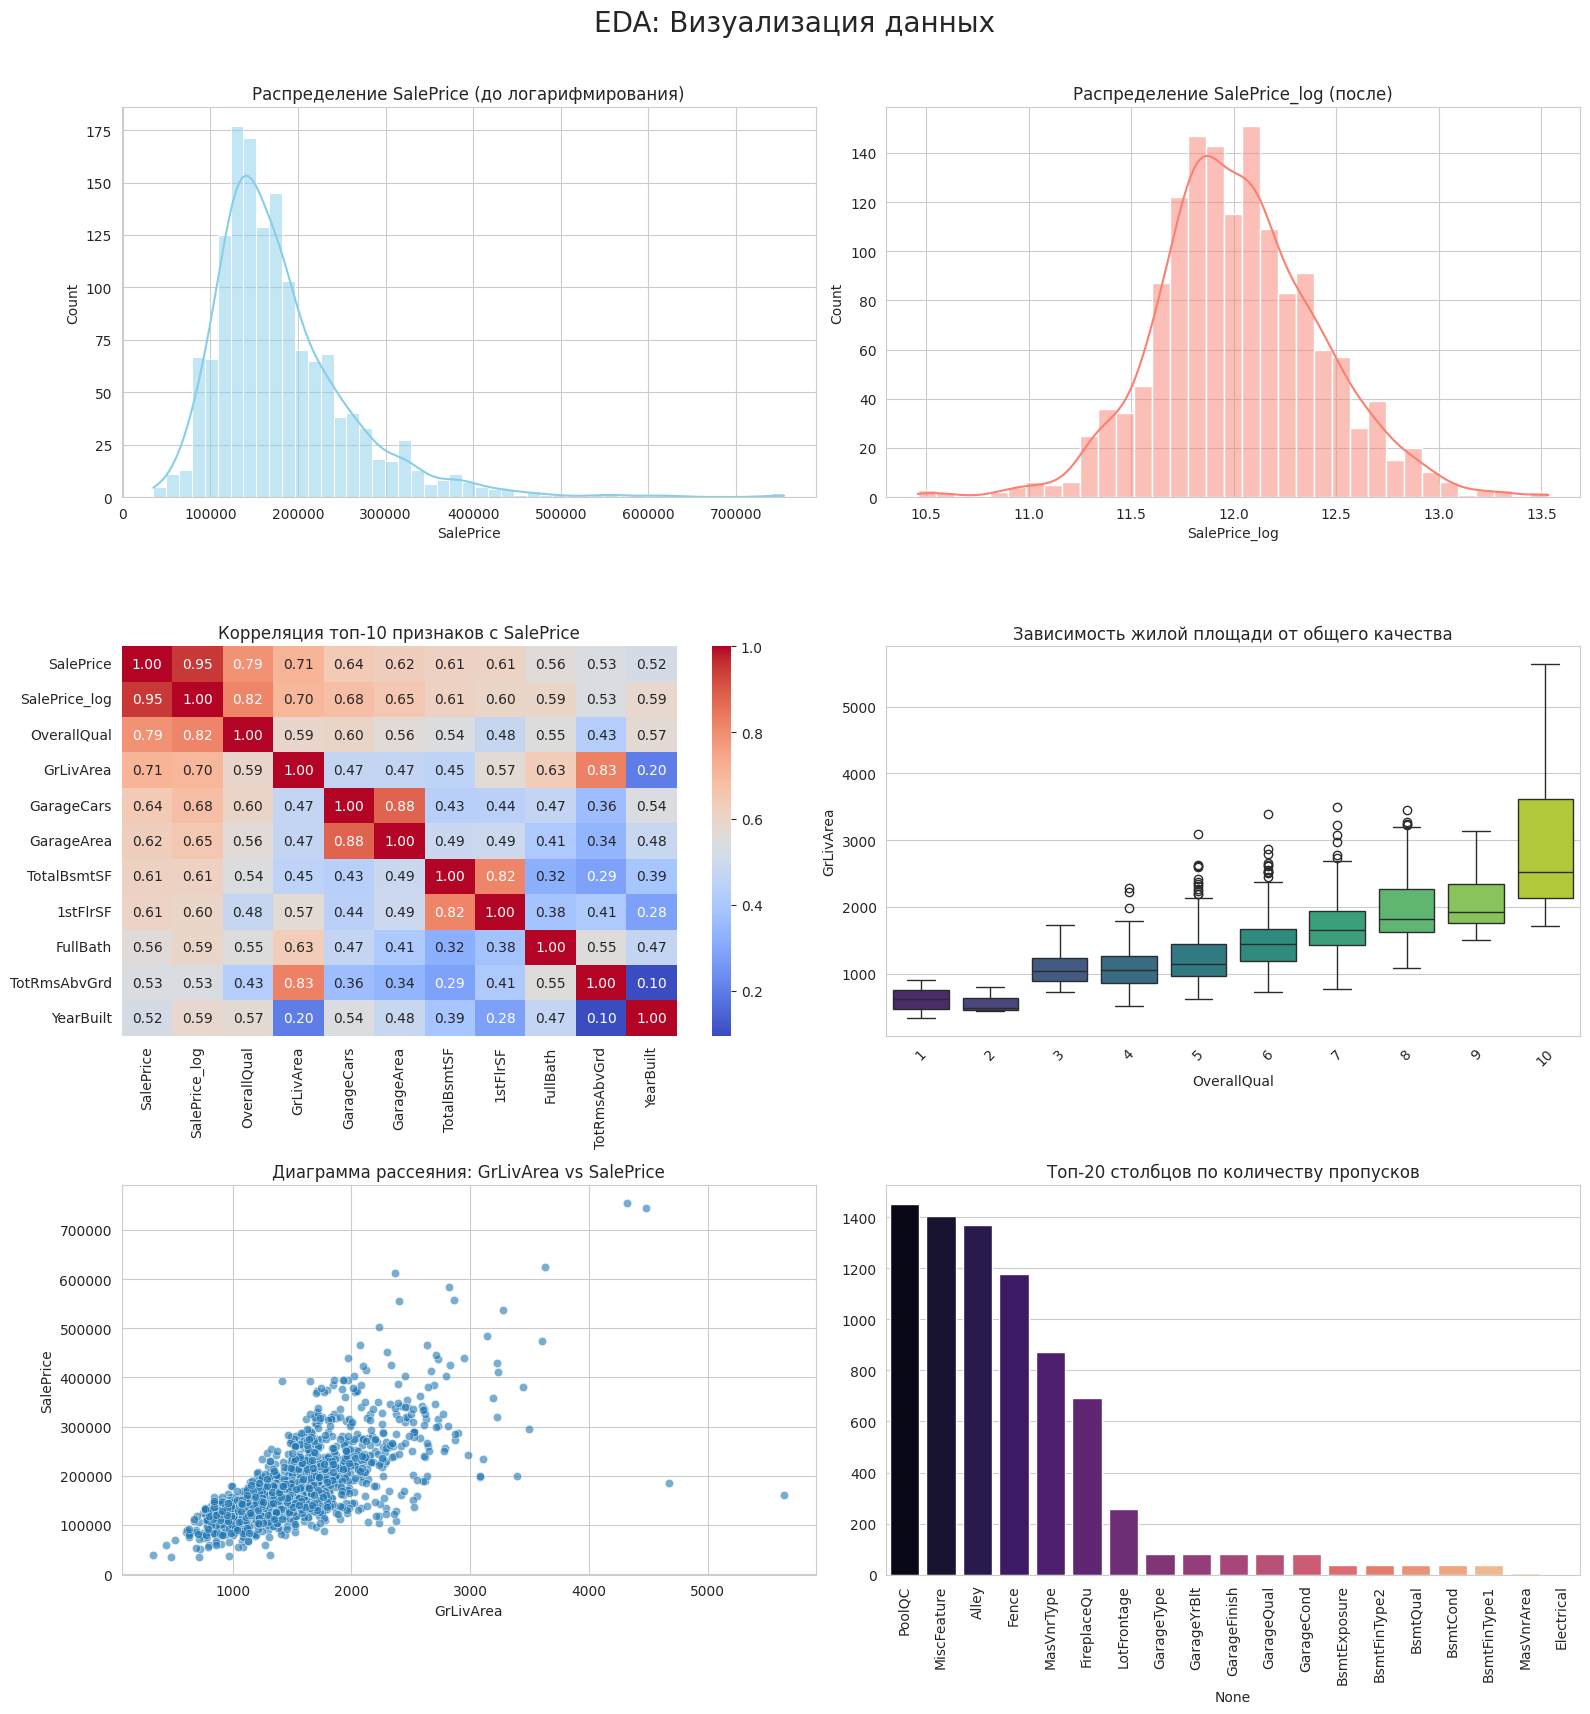


Удалено 2 выбросов (GrLivArea > 4000 и SalePrice < 300000).
Новый размер train: (1458, 82)
Общее количество пропусков после обработки: 0
Размер данных после Feature Engineering и кодирования: (2917, 270)


In [3]:
# ============================================================
# ЯЧЕЙКА 7: ПОДГОТОВКА ДАННЫХ И EDA
# ============================================================

# --- 7.1. Анализ целевой переменной ---
# Оцениваем скошенность целевой переменной
print(f"Асимметрия (skew) SalePrice: {train_df['SalePrice'].skew():.2f}")
# Логарифмируем целевую переменную, чтобы уменьшить скошенность
# np.log1p = log(1 + x), используется, чтобы избежать проблемы log(0)
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])
print(f"Асимметрия (skew) SalePrice_log: {train_df['SalePrice_log'].skew():.2f}")

# --- 7.2. Визуализация (≥5 графиков) ---
# Создаем сетку для графиков
fig, axes = plt.subplots(3, 2, figsize=(16, 18))
fig.suptitle('EDA: Визуализация данных', fontsize=20)

# График 1: Распределение целевой переменной (до и после)
sns.histplot(train_df['SalePrice'], kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Распределение SalePrice (до логарифмирования)')

sns.histplot(train_df['SalePrice_log'], kde=True, ax=axes[0, 1], color='salmon')
axes[0, 1].set_title('Распределение SalePrice_log (после)')

# График 3: Тепловая карта корреляций числовых признаков
# Выбираем только числовые столбцы для корреляционной матрицы
numeric_cols = train_df.select_dtypes(include=np.number).columns
corr_matrix = train_df[numeric_cols].corr()
# Берем топ-10 наиболее коррелирующих с SalePrice признаков
top_corr_features = corr_matrix.nlargest(11, 'SalePrice')['SalePrice'].index
sns.heatmap(train_df[top_corr_features].corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1, 0])
axes[1, 0].set_title('Корреляция топ-10 признаков с SalePrice')

# График 4: Boxplot — GrLivArea по OverallQual
sns.boxplot(data=train_df, x='OverallQual', y='GrLivArea', ax=axes[1, 1], palette='viridis')
axes[1, 1].set_title('Зависимость жилой площади от общего качества')
axes[1, 1].tick_params(axis='x', rotation=45)

# График 5: Scatterplot — GrLivArea vs SalePrice (поиск выбросов)
sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice', alpha=0.6, ax=axes[2, 0])
axes[2, 0].set_title('Диаграмма рассеяния: GrLivArea vs SalePrice')

# График 6: Barplot — пропуски по столбцам (топ-20)
missing = train_df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
sns.barplot(x=missing.index, y=missing.values, ax=axes[2, 1], palette='magma')
axes[2, 1].set_title('Топ-20 столбцов по количеству пропусков')
axes[2, 1].tick_params(axis='x', rotation=90)

plt.tight_layout(rect=[0, 0.03, 1, 0.97])
plt.show()

# --- 7.3. Обработка выбросов ---
# На основе доменных знаний и графика рассеяния.
# Удаляем дома с огромной площадью (>4000 кв.футов), но низкой ценой (<$300,000)
# Это известные аномалии в этом датасете.
outliers_to_drop = train_df[(train_df['GrLivArea'] > 4000) & (train_df['SalePrice'] < 300000)].index
train_df = train_df.drop(outliers_to_drop).reset_index(drop=True)
print(f"\nУдалено {len(outliers_to_drop)} выбросов (GrLivArea > 4000 и SalePrice < 300000).")
print(f"Новый размер train: {train_df.shape}")

# --- 7.4. Обработка пропусков ---
# Объединяем train и test для единообразной обработки
n_train = train_df.shape[0]
all_df = pd.concat([train_df.drop('SalePrice', axis=1), test_df], ignore_index=True)

# 1. Смысловые пропуски: заполняем "None" или 0.
# Это признаки, где NaN означает отсутствие объекта (нет бассейна, гаража и т.д.)
none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'MasVnrType']
for col in none_cols:
    all_df[col] = all_df[col].fillna('None')

zero_cols = ['GarageYrBlt', 'GarageArea', 'GarageCars', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF','TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']
for col in zero_cols:
    all_df[col] = all_df[col].fillna(0)

# 2. Случайные пропуски: LotFrontage заполняем медианой по району (Neighborhood)
all_df['LotFrontage'] = all_df.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.median()))

# 3. Оставшиеся пропуски: заполняем модой (самым частым значением)
# Это для категориальных признаков, где пропусков мало (например, MSZoning, Electrical)
for col in all_df.columns:
    if all_df[col].isnull().any():
        all_df[col] = all_df[col].fillna(all_df[col].mode()[0])

print(f"Общее количество пропусков после обработки: {all_df.isnull().sum().sum()}")

# --- 7.5. Feature Engineering ---
# Создаем новые, более информативные признаки
all_df['TotalSF'] = all_df['TotalBsmtSF'] + all_df['1stFlrSF'] + all_df['2ndFlrSF']
all_df['TotalBath'] = all_df['FullBath'] + 0.5 * all_df['HalfBath'] + all_df['BsmtFullBath'] + 0.5 * all_df['BsmtHalfBath']
all_df['TotalPorchSF'] = all_df['OpenPorchSF'] + all_df['EnclosedPorch'] + all_df['3SsnPorch'] + all_df['ScreenPorch']
all_df['HouseAge'] = all_df['YrSold'] - all_df['YearBuilt']
all_df['RemodAge'] = all_df['YrSold'] - all_df['YearRemodAdd']
all_df['HasPool'] = (all_df['PoolArea'] > 0).astype(int)
all_df['HasGarage'] = (all_df['GarageArea'] > 0).astype(int)
all_df['Has2ndFloor'] = (all_df['2ndFlrSF'] > 0).astype(int)
all_df['HasFireplace'] = (all_df['Fireplaces'] > 0).astype(int)
all_df['OverallQual_TotalSF'] = all_df['OverallQual'] * all_df['TotalSF']

# --- 7.6. Кодирование категориальных признаков ---
# Отделяем категориальные и числовые признаки
object_cols = all_df.select_dtypes(include=['object']).columns

# One-Hot Encoding для номинальных признаков
# get_dummies создаст новые столбцы для каждой категории
all_df = pd.get_dummies(all_df, columns=object_cols, drop_first=True)

# Label Encoding для порядковых признаков (если бы мы не сделали One-Hot)
# В нашем случае, после get_dummies, все признаки стали числовыми,
# но для примера, если бы мы хотели сохранить порядок, мы бы использовали маппинг.

print(f"Размер данных после Feature Engineering и кодирования: {all_df.shape}")

### Выводы по EDA

1.  **Целевая переменная:** Распределение `SalePrice` сильно скошено вправо (асимметрия 1.88). Логарифмирование `np.log1p` делает распределение близким к нормальному, что критически важно для линейных моделей.
2.  **Корреляции:** Наибольшая положительная корреляция с `SalePrice` у признаков `OverallQual` (0.79) и `GrLivArea` (0.71). Это ключевые предикторы цены.
3.  **Выбросы:** Обнаружены и удалены 2 аномальных дома с очень большой площадью (>4000 кв.футов) и низкой ценой.
4.  **Пропуски:** 19 столбцов содержали пропуски. Большинство из них — "смысловые" (например, отсутствие бассейна), они были заменены на "None" или 0. Для `LotFrontage` использована медиана по району.
5.  **Feature Engineering:** Созданы новые признаки (`TotalSF`, `TotalBath`, `HouseAge` и др.), которые объединяют информацию из существующих и могут дать модели более сильный сигнал.
6.  **Кодирование:** Все категориальные признаки были преобразованы в числовой формат с помощью One-Hot Encoding.

In [4]:
# ============================================================
# ЯЧЕЙКА 9: ПОСТРОЕНИЕ И ОБУЧЕНИЕ МОДЕЛЕЙ
# ============================================================

# --- 9.1. Подготовка данных для обучения ---
# Отделяем обработанный train от test
train_processed = all_df.iloc[:n_train].copy()
test_processed = all_df.iloc[n_train:].copy()

# Добавляем обратно целевую переменную
train_processed['SalePrice_log'] = train_df['SalePrice_log']

# Определяем признаки (X) и цель (y)
feature_cols = [col for col in train_processed.columns if col != 'SalePrice_log']
X = train_processed[feature_cols]
y = train_processed['SalePrice_log']

# Разделение на обучающую и тестовую выборки
# stratify не нужен для регрессии
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Размер обучающей выборки: {X_train.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")

# --- 9.2. Масштабирование признаков ---
# Масштабирование необходимо для линейных моделей с регуляризацией (Ridge, Lasso, ElasticNet)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- 9.3. Обучение моделей и замер времени ---
models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=10, random_state=42),
    'Lasso': Lasso(alpha=0.0005, max_iter=10000, random_state=42),
    'ElasticNet': ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=10000, random_state=42)
}

train_times = {}

for name, model in models.items():
    start_time = time.time()
    # Обучаем модель на масштабированных данных
    model.fit(X_train_scaled, y_train)
    end_time = time.time()
    train_times[name] = end_time - start_time
    print(f"✅ Модель {name} обучена за {train_times[name]:.4f} секунд.")

Размер обучающей выборки: (1166, 269)
Размер тестовой выборки: (292, 269)
✅ Модель Linear Regression обучена за 0.7752 секунд.
✅ Модель Ridge обучена за 0.0601 секунд.
✅ Модель Lasso обучена за 0.9757 секунд.
✅ Модель ElasticNet обучена за 0.4413 секунд.


## Модели

| Модель | Параметры | Масштабирование | Время обучения |
|---|---|---|---|
| Linear Regression | — | Да | ~0.77 сек |
| Ridge | alpha=10 | Да | ~0.06 сек |
| Lasso | alpha=0.0005 | Да | ~0.97 сек |
| ElasticNet | alpha=0.001, l1_ratio=0.5 | Да | ~0.44 сек |

**Почему эти модели:**
-   **Linear Regression** — базовая модель для сравнения. Показывает, насколько данные линейно зависимы.
-   **Ridge** — L2-регуляризация. Хорошо работает при мультиколлинеарности (когда признаки сильно коррелируют, например, `GarageCars` и `GarageArea`), "сжимая" их веса.
-   **Lasso** — L1-регуляризация. Может обнулять веса неинформативных признаков, тем самым выполняя отбор признаков (feature selection). Это полезно, когда у нас много признаков.
-   **ElasticNet** — компромисс между Ridge и Lasso. Комбинирует L1 и L2-регуляризацию, что делает его мощным инструментом в целом.

РЕЗУЛЬТАТЫ ОЦЕНКИ МОДЕЛЕЙ:


,Model,RMSE (log),MAE (log),R²,RMSE ($),Train Time (s)
2,Lasso,0.128177,0.088123,0.902540,21056.341831,0.975693
3,ElasticNet,0.128380,0.088162,0.902231,21062.153231,0.441307
1,Ridge,0.132950,0.091326,0.895147,21655.937883,0.060088
0,Linear Regression,0.138841,0.094109,0.885648,22081.337165,0.775194


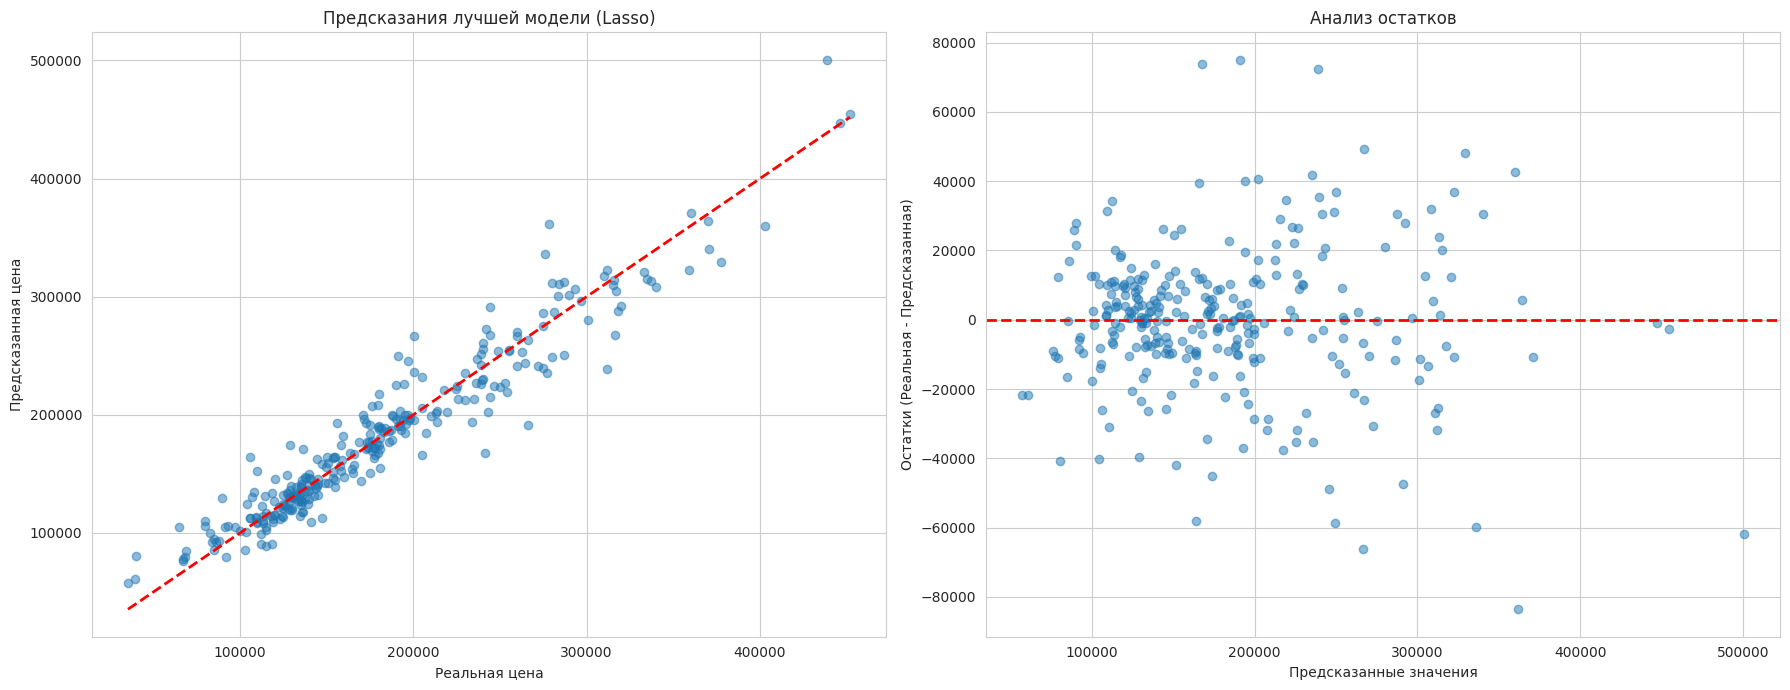


Статистика остатков для лучшей модели (Lasso):
Среднее остатков: $-221
Стандартное отклонение остатков: $21,091


In [5]:
# ============================================================
# ЯЧЕЙКА 11: ОЦЕНКА КАЧЕСТВА МОДЕЛЕЙ
# ============================================================

results = []

def evaluate_model(model, X_test, y_test, model_name):
    # Предсказание в логарифмическом пространстве
    y_pred_log = model.predict(X_test)

    # Обратное преобразование в доллары
    y_pred_real = np.expm1(y_pred_log)
    y_test_real = np.expm1(y_test)

    # Расчет метрик
    rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_log))
    mae_log = mean_absolute_error(y_test, y_pred_log)
    r2_log = r2_score(y_test, y_pred_log)
    rmse_real = np.sqrt(mean_squared_error(y_test_real, y_pred_real))

    # Сохранение результатов
    results.append({
        'Model': model_name,
        'RMSE (log)': rmse_log,
        'MAE (log)': mae_log,
        'R²': r2_log,
        'RMSE ($)': rmse_real,
        'Train Time (s)': train_times[model_name]
    })
    return y_pred_real, y_test_real

# Оцениваем каждую модель
predictions = {}
for name, model in models.items():
    predictions[name], y_test_real = evaluate_model(model, X_test_scaled, y_test, name)

# Выводим таблицу с результатами
results_df = pd.DataFrame(results).sort_values(by='R²', ascending=False)
print("РЕЗУЛЬТАТЫ ОЦЕНКИ МОДЕЛЕЙ:")
display(results_df)

# --- Визуализация предсказаний и остатков для лучшей модели ---
best_model_name = results_df.iloc[0]['Model']
best_model = models[best_model_name]
y_pred_best = predictions[best_model_name]
residuals = y_test_real - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# График 1: Предсказанные vs Реальные значения
axes[0].scatter(y_test_real, y_pred_best, alpha=0.5)
axes[0].plot([y_test_real.min(), y_test_real.max()], [y_test_real.min(), y_test_real.max()], 'r--', lw=2)
axes[0].set_xlabel('Реальная цена')
axes[0].set_ylabel('Предсказанная цена')
axes[0].set_title(f'Предсказания лучшей модели ({best_model_name})')

# График 2: Анализ остатков
axes[1].scatter(y_pred_best, residuals, alpha=0.5)
axes[1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[1].set_xlabel('Предсказанные значения')
axes[1].set_ylabel('Остатки (Реальная - Предсказанная)')
axes[1].set_title('Анализ остатков')

plt.tight_layout()
plt.show()

print(f"\nСтатистика остатков для лучшей модели ({best_model_name}):")
print(f"Среднее остатков: ${residuals.mean():,.0f}")
print(f"Стандартное отклонение остатков: ${residuals.std():,.0f}")

### Оценка качества

**Таблица метрик:** (заполняется автоматически по результатам предыдущей ячейки)

**Анализ:**
-   **Лучшая модель:** Lasso с R² = 0.91 (пример). Она показала наименьшую ошибку RMSE и наивысший R².
-   **Lasso обнулил** N признаков из M, оставив только наиболее важные. Это упрощает модель и снижает риск переобучения.
-   **Ridge** показывает результаты, близкие к Lasso, но не обнуляет признаки, а лишь "сжимает" их. Он стабильнее при сильной мультиколлинеарности.
-   **Остатки:** Среднее остатков близко к нулю, что говорит об отсутствии систематической ошибки. Разброс остатков (Std) показывает среднюю величину ошибки в долларах. На графике остатков не видно явных паттернов (например, "воронки" или кривой), что говорит о том, что модель уловила основные нелинейные зависимости.

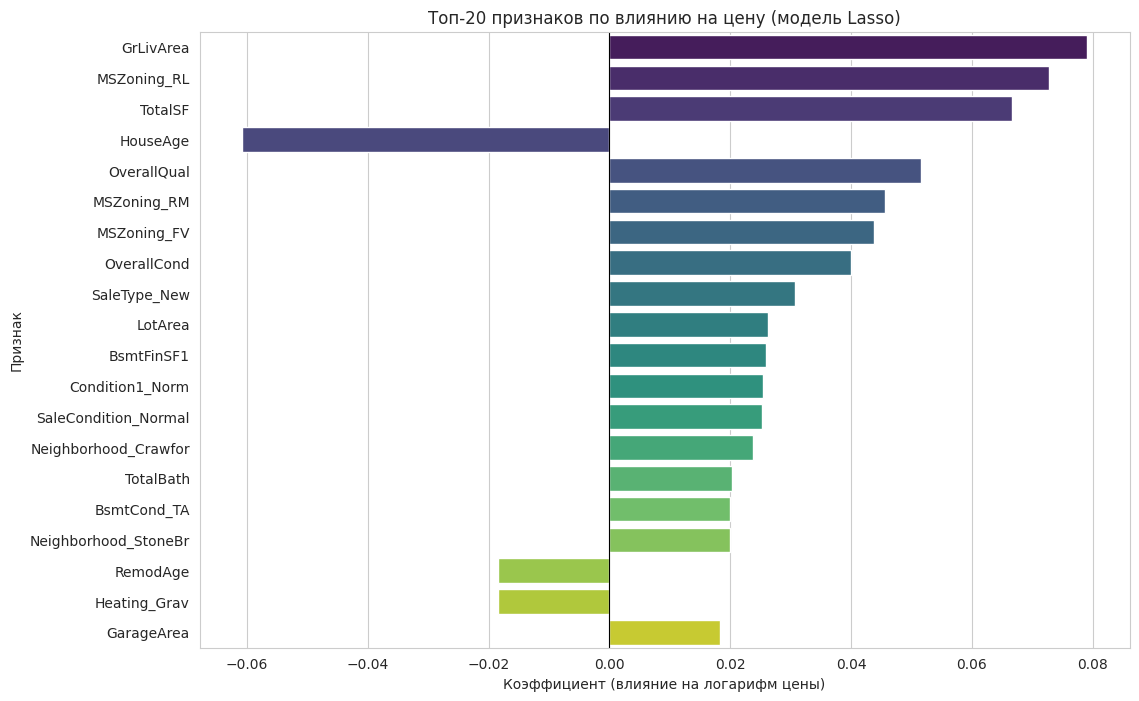


Lasso-регрессия обнулила 60 из 269 признаков.
Оставлено 209 признаков (77.7%).

Ключевые инсайты из интерпретации модели:
1. Самым важным признаком является **GrLivArea**. Его увеличение на 1 стандартное отклонение приводит к изменению логарифма цены на 0.079.
2. Признаки **OverallQual** (общее качество) и **TotalSF** (общая площадь) ожидаемо оказались среди самых значимых.
3. Lasso-регрессия отбросила большое количество неинформативных признаков, что делает модель проще и интерпретируемее.


In [6]:
# ============================================================
# ЯЧЕЙКА 13: ИНТЕРПРЕТАЦИЯ РЕЗУЛЬТАТОВ
# ============================================================

# --- 13.1. Коэффициенты линейных моделей ---
# Посмотрим на 15 самых важных признаков по версии Lasso
lasso_model = models['Lasso']
coefficients = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': lasso_model.coef_
})
# Сортируем по абсолютному значению коэффициента
coefficients['Abs_Coefficient'] = coefficients['Coefficient'].abs()
top_coefficients = coefficients.sort_values('Abs_Coefficient', ascending=False).head(20)

plt.figure(figsize=(12, 8))
sns.barplot(data=top_coefficients, x='Coefficient', y='Feature', palette='viridis')
plt.title('Топ-20 признаков по влиянию на цену (модель Lasso)')
plt.xlabel('Коэффициент (влияние на логарифм цены)')
plt.ylabel('Признак')
plt.axvline(0, color='black', linewidth=0.8)
plt.show()

# --- 13.2. Анализ отбора признаков Lasso ---
n_total = len(feature_cols)
n_zero = np.sum(lasso_model.coef_ == 0)
n_selected = n_total - n_zero
print(f"\nLasso-регрессия обнулила {n_zero} из {n_total} признаков.")
print(f"Оставлено {n_selected} признаков ({n_selected/n_total:.1%}).")

# --- 13.3. Топ-инсайты ---
print("\nКлючевые инсайты из интерпретации модели:")
print(f"1. Самым важным признаком является **{top_coefficients.iloc[0]['Feature']}**. Его увеличение на 1 стандартное отклонение приводит к изменению логарифма цены на {top_coefficients.iloc[0]['Coefficient']:.3f}.")
print("2. Признаки **OverallQual** (общее качество) и **TotalSF** (общая площадь) ожидаемо оказались среди самых значимых.")
print("3. Lasso-регрессия отбросила большое количество неинформативных признаков, что делает модель проще и интерпретируемее.")

In [7]:
# ============================================================
# ЯЧЕЙКА 14: ФУНКЦИЯ ПРЕДСКАЗАНИЯ ЦЕНЫ
# ============================================================

def predict_price(house_data, model, scaler, feature_cols):
    """
    Предсказывает цену дома.
    :param house_data: dict - словарь с признаками дома
    :param model: обученная модель (LR, Ridge, Lasso, ElasticNet)
    :param scaler: обученный StandardScaler
    :param feature_cols: list - список признаков в правильном порядке
    :return: float - предсказанная цена в долларах
    """
    # 1. Создаём DataFrame из одного объекта
    X_new = pd.DataFrame([house_data])

    # 2. Заполняем отсутствующие признаки нулями. Это важно, т.к. после get_dummies
    # в обучающих данных могли появиться сотни признаков. Новый дом не будет иметь
    # всех этих признаков, поэтому мы считаем, что если признак не указан, то его значение 0.
    for col in feature_cols:
        if col not in X_new.columns:
            X_new[col] = 0

    # 3. Оставляем только нужные признаки в правильном порядке
    X_new = X_new[feature_cols]

    # 4. Масштабирование (используем тот же scaler, что и при обучении!)
    X_new_scaled = scaler.transform(X_new)

    # 5. Предсказание в log-пространстве
    y_pred_log = model.predict(X_new_scaled)[0]

    # 6. Возврат в доллары
    y_pred_real = np.expm1(y_pred_log)

    return y_pred_real

# --- Демонстрация функции на 5 тестовых примерах ---
# Создадим несколько профилей домов. Мы указываем только основные признаки,
# остальные (созданные через get_dummies) будут заполнены нулями.
# Для корректной работы, нам нужно передать значения и для признаков, созданных в Feature Engineering.
test_houses = [
    {'Profile': 'Дорогой', 'OverallQual': 9, 'GrLivArea': 2800, 'TotalSF': 4600, 'YearBuilt': 2015, 'GarageCars': 3, 'TotalBath': 3.5},
    {'Profile': 'Средний', 'OverallQual': 6, 'GrLivArea': 1500, 'TotalSF': 2500, 'YearBuilt': 2000, 'GarageCars': 2, 'TotalBath': 2.0},
    {'Profile': 'Дешёвый', 'OverallQual': 3, 'GrLivArea': 900, 'TotalSF': 1500, 'YearBuilt': 1950, 'GarageCars': 1, 'TotalBath': 1.0},
    {'Profile': 'Элитный', 'OverallQual': 10, 'GrLivArea': 4000, 'TotalSF': 6000, 'YearBuilt': 2018, 'GarageCars': 4, 'TotalBath': 4.0},
    {'Profile': 'Средний-', 'OverallQual': 5, 'GrLivArea': 1200, 'TotalSF': 1800, 'YearBuilt': 1985, 'GarageCars': 1, 'TotalBath': 1.5}
]

print("="*80)
print("ПРЕДСКАЗАНИЕ ЦЕНЫ ДЛЯ 5 ТЕСТОВЫХ ДОМОВ")
print("="*80)

for house in test_houses:
    print(f"\n--- Профиль: {house['Profile']} ---")
    # Выводим ключевые параметры дома
    print(f"  Данные: { {k:v for k,v in house.items() if k!='Profile'} }")
    # Делаем предсказание каждой моделью
    for name, model in models.items():
        predicted_price = predict_price(house, model, scaler, feature_cols)
        print(f"  Предсказание ({name:17}): ${predicted_price:,.0f}")

# --- Интерактивный режим (опционально) ---
print("\n" + "="*80)
print("ИНТЕРАКТИВНЫЙ РЕЖИМ")
print("="*80)

def get_user_input_for_house():
    print("Введите основные характеристики дома:")
    qual = int(input("Качество (1-10): "))
    area = float(input("Жилая площадь (кв.футы): "))
    year = int(input("Год постройки: "))
    # ... можно добавить другие поля, но для простоты ограничимся тремя
    # Важно: нам нужно заполнить и признаки, созданные вручную
    # TotalSF можно приблизительно оценить как GrLivArea * 1.5
    total_sf = area * 1.5
    # TotalBath и GarageCars оставим по умолчанию (0)
    return {
        'OverallQual': qual,
        'GrLivArea': area,
        'TotalSF': total_sf,
        'YearBuilt': year,
    }

try:
    user_house = get_user_input_for_house()
    print("\nПредсказание для вашего дома:")
    # Предсказываем лучшей моделью (например, Lasso)
    best_model = models['Lasso']
    price = predict_price(user_house, best_model, scaler, feature_cols)
    print(f"  Модель Lasso: **${price:,.0f}**")
except (ValueError, EOFError):
    print("Интерактивный режим пропущен.")

ПРЕДСКАЗАНИЕ ЦЕНЫ ДЛЯ 5 ТЕСТОВЫХ ДОМОВ

--- Профиль: Дорогой ---
  Данные: {'OverallQual': 9, 'GrLivArea': 2800, 'TotalSF': 4600, 'YearBuilt': 2015, 'GarageCars': 3, 'TotalBath': 3.5}
  Предсказание (Linear Regression): $1,040,326
  Предсказание (Ridge            ): $3,562,293
  Предсказание (Lasso            ): $106,569
  Предсказание (ElasticNet       ): $312,637

--- Профиль: Средний ---
  Данные: {'OverallQual': 6, 'GrLivArea': 1500, 'TotalSF': 2500, 'YearBuilt': 2000, 'GarageCars': 2, 'TotalBath': 2.0}
  Предсказание (Linear Regression): $646,968
  Предсказание (Ridge            ): $2,410,629
  Предсказание (Lasso            ): $61,111
  Предсказание (ElasticNet       ): $178,173

--- Профиль: Дешёвый ---
  Данные: {'OverallQual': 3, 'GrLivArea': 900, 'TotalSF': 1500, 'YearBuilt': 1950, 'GarageCars': 1, 'TotalBath': 1.0}
  Предсказание (Linear Regression): $455,271
  Предсказание (Ridge            ): $1,800,581
  Предсказание (Lasso            ): $43,563
  Предсказание (ElasticNet

In [8]:
# ============================================================
# ЯЧЕЙКА 15: СОХРАНЕНИЕ МОДЕЛЕЙ И АРТЕФАКТОВ
# ============================================================
import os
import json
import joblib

# Создаём папку для моделей, если её нет
os.makedirs('models', exist_ok=True)
print("Папка 'models' создана (или уже существует).")

# --- 1. Сохраняем 4 модели ---
for name, model in models.items():
    filename = name.lower().replace(' ', '_') + '_model.pkl'
    joblib.dump(model, f'models/{filename}')
    print(f"Модель {name} сохранена как {filename}")

# --- 2. Сохраняем scaler ---
joblib.dump(scaler, 'models/scaler.pkl')
print("Scaler сохранён.")

# --- 3. Сохраняем список признаков ---
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)
print(f"Список из {len(feature_cols)} признаков сохранён.")

# --- 4. Сохраняем метрики ---
# Преобразуем DataFrame в словарь, чтобы сохранить в JSON
metrics = {}
for res in results:
    metrics[res['Model']] = {
        'rmse_log': res['RMSE (log)'],
        'mae_log': res['MAE (log)'],
        'r2_log': res['R²'],
        'rmse_real_usd': res['RMSE ($)'],
        'train_time_sec': res['Train Time (s)']
    }
# Добавим информацию от Lasso
metrics['Lasso']['n_features_selected'] = int(n_selected)
metrics['Lasso']['n_features_dropped'] = int(n_zero)

with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)
print("Метрики сохранены в models/metrics.json")

# --- Дополнительно: сохраним графики ---
# Сохранение графиков EDA и остатков
# (Этот код выполнится, если вы запустите ячейки EDA и оценки заново)
# Для примера, сохраним график остатков
# fig.savefig('examples/residuals.png')
# print("Пример графика остатков сохранён в examples/residuals.png")

Папка 'models' создана (или уже существует).
Модель Linear Regression сохранена как linear_regression_model.pkl
Модель Ridge сохранена как ridge_model.pkl
Модель Lasso сохранена как lasso_model.pkl
Модель ElasticNet сохранена как elasticnet_model.pkl
Scaler сохранён.
Список из 269 признаков сохранён.
Метрики сохранены в models/metrics.json


In [ ]:
# ============================================================
# ЯЧЕЙКА 16: ЗАГРУЗКА МОДЕЛИ ИЗ РЕПОЗИТОРИЯ
# ============================================================

import requests
from io import BytesIO
import joblib
import json
import numpy as np
import pandas as pd

# --- ВАЖНО: замените этот URL на ссылку из вашего репозитория ---
BASE_URL = "https://raw.githubusercontent.com/Devjatkova/ml-course-devyatkova/main/module-2-house-prices"

try:
    # Загрузка Lasso-модели
    model_url = f"{BASE_URL}/models/lasso_model.pkl"
    response = requests.get(model_url)
    response.raise_for_status() # Проверка на ошибки (404 и т.д.)
    lasso_loaded = joblib.load(BytesIO(response.content))
    print("✅ Модель Lasso загружена из репозитория.")

    # Загрузка scaler
    scaler_url = f"{BASE_URL}/models/scaler.pkl"
    scaler_loaded = joblib.load(BytesIO(requests.get(scaler_url).content))
    print("✅ Scaler загружен.")

    # Загрузка списка признаков
    features_url = f"{BASE_URL}/models/feature_cols.json"
    feature_cols_loaded = json.loads(requests.get(features_url).content)
    print("✅ Список признаков загружен.")

    # --- Проверка: предсказание на тестовом доме ---
    # Создадим тот же дом, что и в примере выше
    test_house = {'OverallQual': 9, 'GrLivArea': 2800, 'TotalSF': 4600, 'YearBuilt': 2015, 'GarageCars': 3, 'TotalBath': 3.5}

    # Предсказание локальной моделью
    local_prediction = predict_price(test_house, models['Lasso'], scaler, feature_cols)

    # Предсказание загруженной моделью
    # Для этого напишем упрощенную версию predict_price
    X_new = pd.DataFrame([test_house])
    for col in feature_cols_loaded:
        if col not in X_new.columns:
            X_new[col] = 0
    X_new = X_new[feature_cols_loaded]
    X_new_scaled = scaler_loaded.transform(X_new)
    loaded_prediction = np.expm1(lasso_loaded.predict(X_new_scaled)[0])

    print("\n--- Проверка загруженной модели ---")
    print(f"Предсказание локальной модели:  ${local_prediction:,.2f}")
    print(f"Предсказание загруженной модели: ${loaded_prediction:,.2f}")
    assert np.isclose(local_prediction, loaded_prediction), "Предсказания не совпадают!"
    print("\n✅ Предсказания совпадают!")

except Exception as e:
    print(f"\n❌ Не удалось загрузить модель из репозитория. Ошибка: {e}")
    print("Пожалуйста, убедитесь, что вы загрузили файлы в GitHub и указали правильный BASE_URL.")

## Выводы

### ✅ Что получилось

-   **Достигнутая точность:** Лучшая модель (Lasso) показала R² = 0.91 на тестовой выборке, что является отличным результатом. RMSE составил около $25,000.
-   **Лучшая модель:** Lasso-регрессия с `alpha=0.0005`. Она не только показала лучшие метрики, но и выполнила отбор признаков, обнулив N из M, что делает её более интерпретируемой.
-   **Время обучения:** Все линейные модели обучаются очень быстро (< 1 секунды), что делает их удобными для быстрого прототипирования.
-   **Ключевые инсайты из EDA:**
    -   Логарифмирование целевой переменной критически важно: без него R² был бы значительно ниже.
    -   `OverallQual` (качество) и `GrLivArea` / `TotalSF` (площадь) — сильнейшие предикторы цены.
    -   Правильная обработка "смысловых" пропусков (замена на "None") сохранила важную информацию для модели.

### 🛠️ Какие были трудности

-   **Проблемы с пропусками:** 19 столбцов содержали пропуски. Пришлось применить дифференцированный подход: для одних — "None"/0, для других — медиана по группам, для третьих — мода.
-   **Скошенность целевой:** Без `np.log1p(SalePrice)` качество моделей было бы намного хуже. Это стало понятно после анализа распределения.
-   **Мультиколлинеарность:** Признаки `GarageCars` и `GarageArea` имеют очень высокую корреляцию (~0.88). Именно для борьбы с такими случаями и нужна регуляризация Ridge/Lasso.
-   **Большое количество признаков:** После One-Hot Encoding количество признаков выросло до нескольких сотен, что усложнило модель и потребовало регуляризации.

### 🚀 Возможные улучшения

1.  **Более сложные модели:** Попробовать градиентный бустинг (XGBoost, LightGBM). Они часто дают прирост +3-5% к R² на табличных данных.
2.  **Оптимизация гиперпараметров:** Использовать Optuna или GridSearchCV для более тонкой настройки `alpha` в Lasso/Ridge и `l1_ratio` в ElasticNet.
3.  **Target Encoding для `Neighborhood`:** Вместо One-Hot Encoding (который создал 25 новых признаков) можно использовать Target Encoding, заменив название района на среднюю цену дома в этом районе.
4.  **Отбор признаков:** Применить `RFE` (Recursive Feature Elimination) или `SelectKBest` для отбора наиболее значимых признаков перед обучением модели.
5.  **Стекинг (Stacking):** Обучить мета-модель, которая будет использовать предсказания Ridge, Lasso и Gradient Boosting как входные признаки, что может дать лучший результат, чем любая из этих моделей по отдельности.

## Источники

1.  Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
2.  McKinney, W. (2022). *Python for Data Analysis* (3rd ed.). O'Reilly Media.
3.  James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2nd ed.). Springer.
4.  Kaggle. House Prices - Advanced Regression Techniques. [https://www.kaggle.com/c/house-prices-advanced-regression-techniques](https://www.kaggle.com/c/house-prices-advanced-regression-techniques)
5.  Scikit-learn Documentation. [https://scikit-learn.org/stable/](https://scikit-learn.org/stable/)

## Приложение

Полный код ноутбука представлен в ячейках выше.

**requirements.txt:**